# 02 - Análise exploratória dos dados brutos

**Objetivo:** Compreender distribuições, relações e eventos antes de qualquer tratamento.

> Execute as células na ordem. As saídas são gravadas nas pastas do projeto.

In [1]:
from pathlib import Path
import sys, warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Localiza a raiz do projeto independentemente de o notebook ser aberto pela pasta raiz ou notebooks.
CANDIDATOS=[Path.cwd(), Path.cwd().parent]
ROOT=next((p.resolve() for p in CANDIDATOS if (p/'dados').exists() and (p/'notebooks').exists()),None)
if ROOT is None: raise FileNotFoundError('Abra o VS Code na pasta projeto_soft_sensor.')
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src.funcoes import *
sns.set_theme(style='whitegrid')
print('Raiz:',ROOT)


Raiz: D:\UNICAMP\Mestrado\AP539_Aprendizado_estatistico\Trabalho\Projeto\projeto_soft_sensor


## Carregamento

In [2]:
dados=carregar_csv(ROOT/'dados/02_intermediarios/dados_sincronizados.csv'); print(dados.shape); display(dados.head())

(8640, 16)


,timestamp,temperatura_interna_C,umidade_relativa_interna_pct,evento_referencia,flag_dado_faltante_aleatorio,flag_valor_fisicamente_impossivel,flag_salto_incompativel_temperatura,flag_falha_comunicacao,temperatura_ambiente_C,umidade_relativa_ar_pct,chuva_acumulada_dia_mm,radiacao_solar_global_W_m2,temperatura_ponto_orvalho_C,velocidade_vento_m_s,direcao_vento_graus,status_sincronizacao
0,2025-10-01 00:00:00-03:00,17.74,93.46,normal,0,0,0,0,16.47,96.71,0.0,0.0,15.94,2.38,114.4,completo
1,2025-10-01 00:05:00-03:00,17.80,94.09,normal,0,0,0,0,16.32,95.65,0.0,0.0,15.62,1.56,115.5,completo
2,2025-10-01 00:10:00-03:00,17.86,93.19,normal,0,0,0,0,16.14,95.57,0.0,0.0,15.43,1.86,113.8,completo
3,2025-10-01 00:15:00-03:00,17.74,94.99,normal,0,0,0,0,15.94,97.50,0.0,0.0,15.54,2.78,113.1,completo
4,2025-10-01 00:20:00-03:00,17.70,94.79,normal,0,0,0,0,15.99,95.89,0.0,0.0,15.34,2.01,114.8,completo


## Estatísticas e ausências

,count,mean,std,min,25%,50%,75%,max,mediana,assimetria,curtose,ausentes_pct
temperatura_interna_C,8573.0,23.652935,15.071219,-54.56,19.1400,23.150,27.0100,124.110,23.150,1.647806,21.098283,0.775463
umidade_relativa_interna_pct,8573.0,77.842087,12.421557,51.48,65.9300,78.560,89.6900,97.520,78.560,-0.119268,-1.356492,0.775463
flag_dado_faltante_aleatorio,8640.0,0.009954,0.099276,0.00,0.0000,0.000,0.0000,1.000,0.000,9.874666,95.531140,0.000000
flag_valor_fisicamente_impossivel,8640.0,0.040046,0.196079,0.00,0.0000,0.000,0.0000,1.000,0.000,4.692596,20.025096,0.000000
flag_salto_incompativel_temperatura,8640.0,0.040046,0.196079,0.00,0.0000,0.000,0.0000,1.000,0.000,4.692596,20.025096,0.000000
flag_falha_comunicacao,8640.0,0.002778,0.052634,0.00,0.0000,0.000,0.0000,1.000,0.000,18.897798,355.209007,0.000000
temperatura_ambiente_C,8640.0,22.296781,5.008655,12.31,17.8375,22.440,26.2600,34.410,22.440,0.087603,-0.858306,0.000000
umidade_relativa_ar_pct,8640.0,78.174443,13.820269,49.17,65.0000,78.385,91.2800,99.000,78.385,-0.048280,-1.361871,0.000000
chuva_acumulada_dia_mm,8640.0,0.458680,1.460213,0.00,0.0000,0.000,0.0000,9.088,0.000,3.998547,17.034936,0.000000
radiacao_solar_global_W_m2,8640.0,224.995992,266.642927,0.00,0.0000,43.100,487.2525,827.840,43.100,0.656554,-1.210237,0.000000


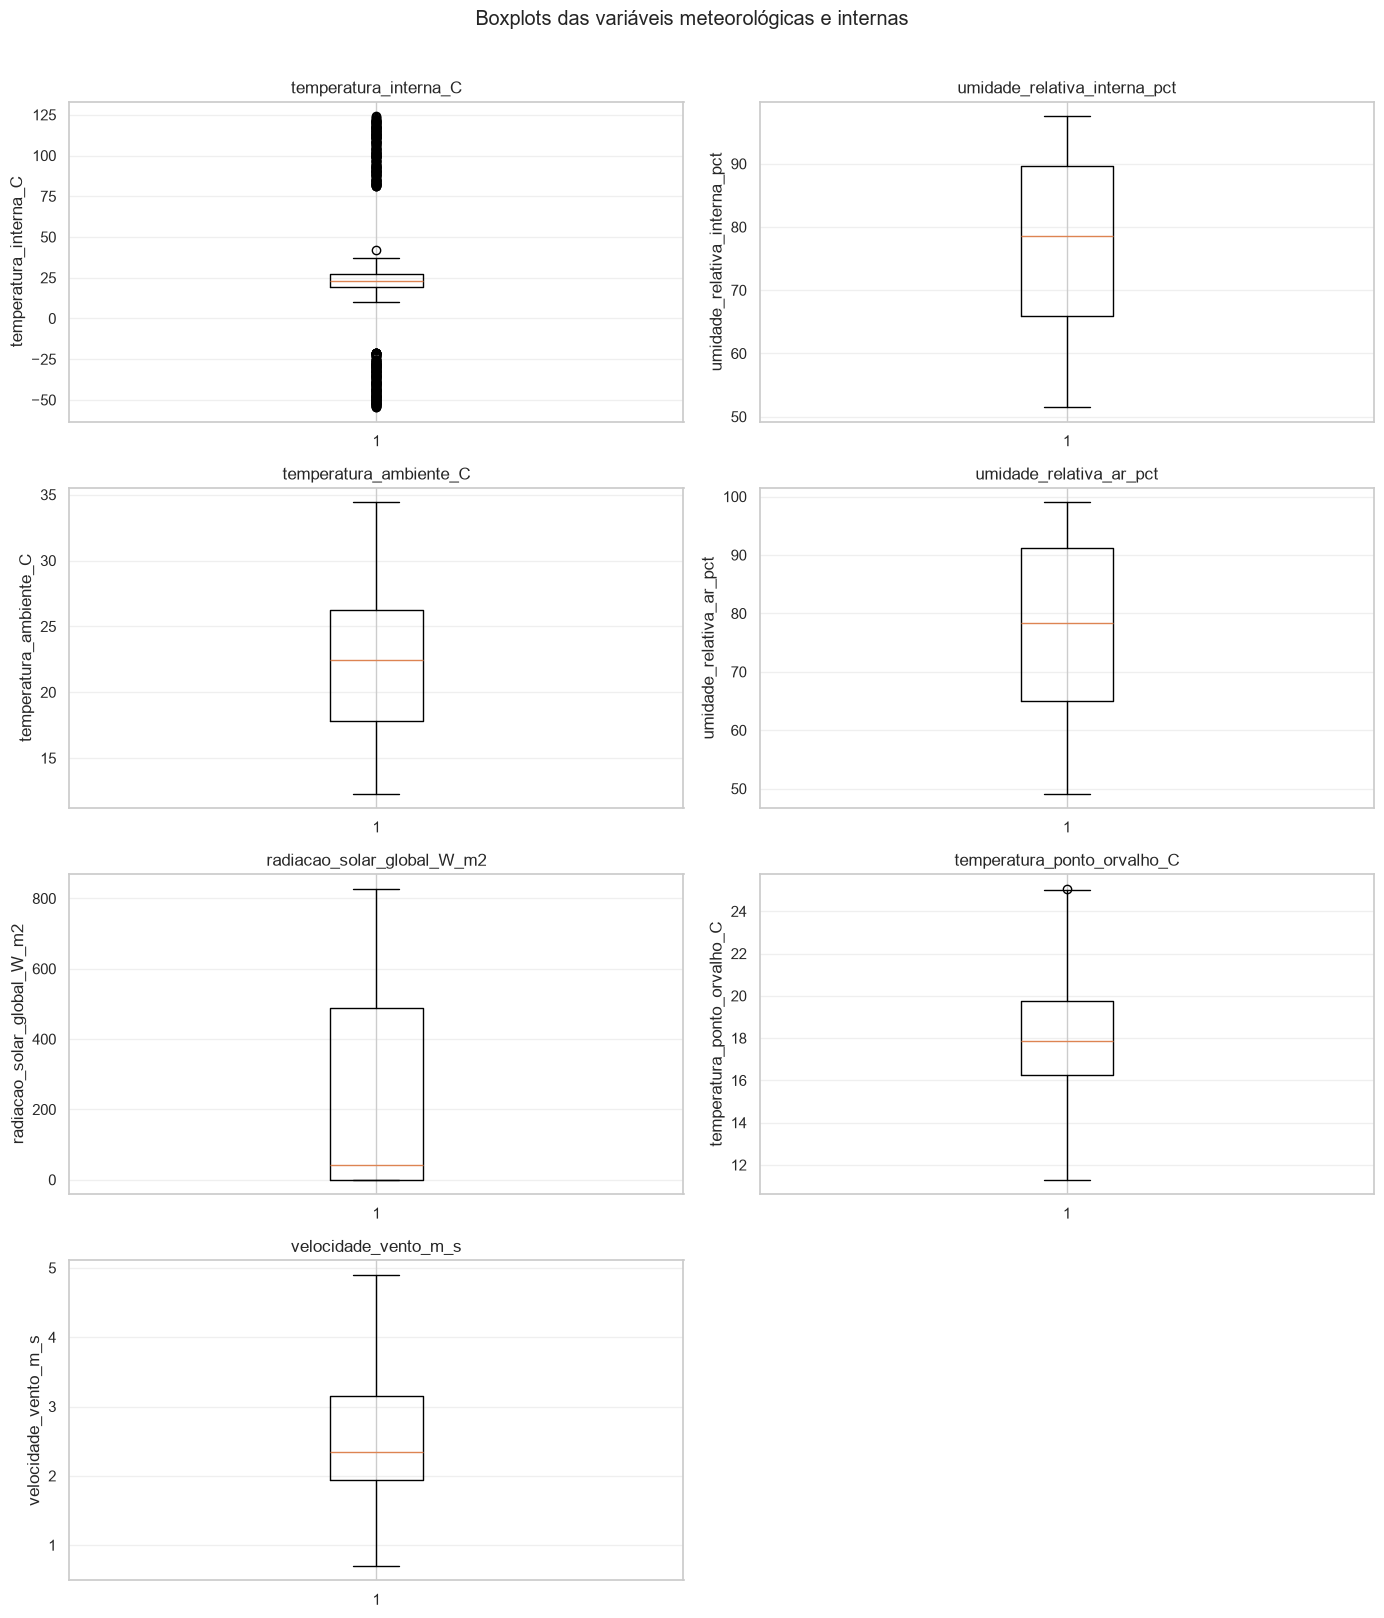

In [10]:
nums=dados.select_dtypes(include='number'); estat=nums.describe().T; estat['mediana']=nums.median(); estat['assimetria']=nums.skew(); estat['curtose']=nums.kurtosis(); estat['ausentes_pct']=nums.isna().mean()*100
display(estat); estat.to_csv(ROOT/'resultados/tabelas/estatisticas_descritivas_brutos.csv',encoding='utf-8-sig')
variaveis_boxplot = [
    'temperatura_interna_C',
    'umidade_relativa_interna_pct',
    'temperatura_ambiente_C',
    'umidade_relativa_ar_pct',
    'radiacao_solar_global_W_m2',
    'temperatura_ponto_orvalho_C',
    'velocidade_vento_m_s'
]
fig, axs = plt.subplots(4, 2, figsize=(14, 16))
for ax, coluna in zip(axs.flat, variaveis_boxplot):
    ax.boxplot(dados[coluna].dropna())
    ax.set_title(coluna)
    ax.set_ylabel(coluna)
    ax.grid(axis='y', alpha=0.3)
axs.flat[-1].set_visible(False)
fig.suptitle('Boxplots das variáveis meteorológicas e internas', y=1.01)
fig.tight_layout()
fig.savefig(ROOT/'resultados/figuras/dados_brutos/boxplots_variaveis_principais.png', dpi=150, bbox_inches='tight')
plt.show()

## Séries temporais principais

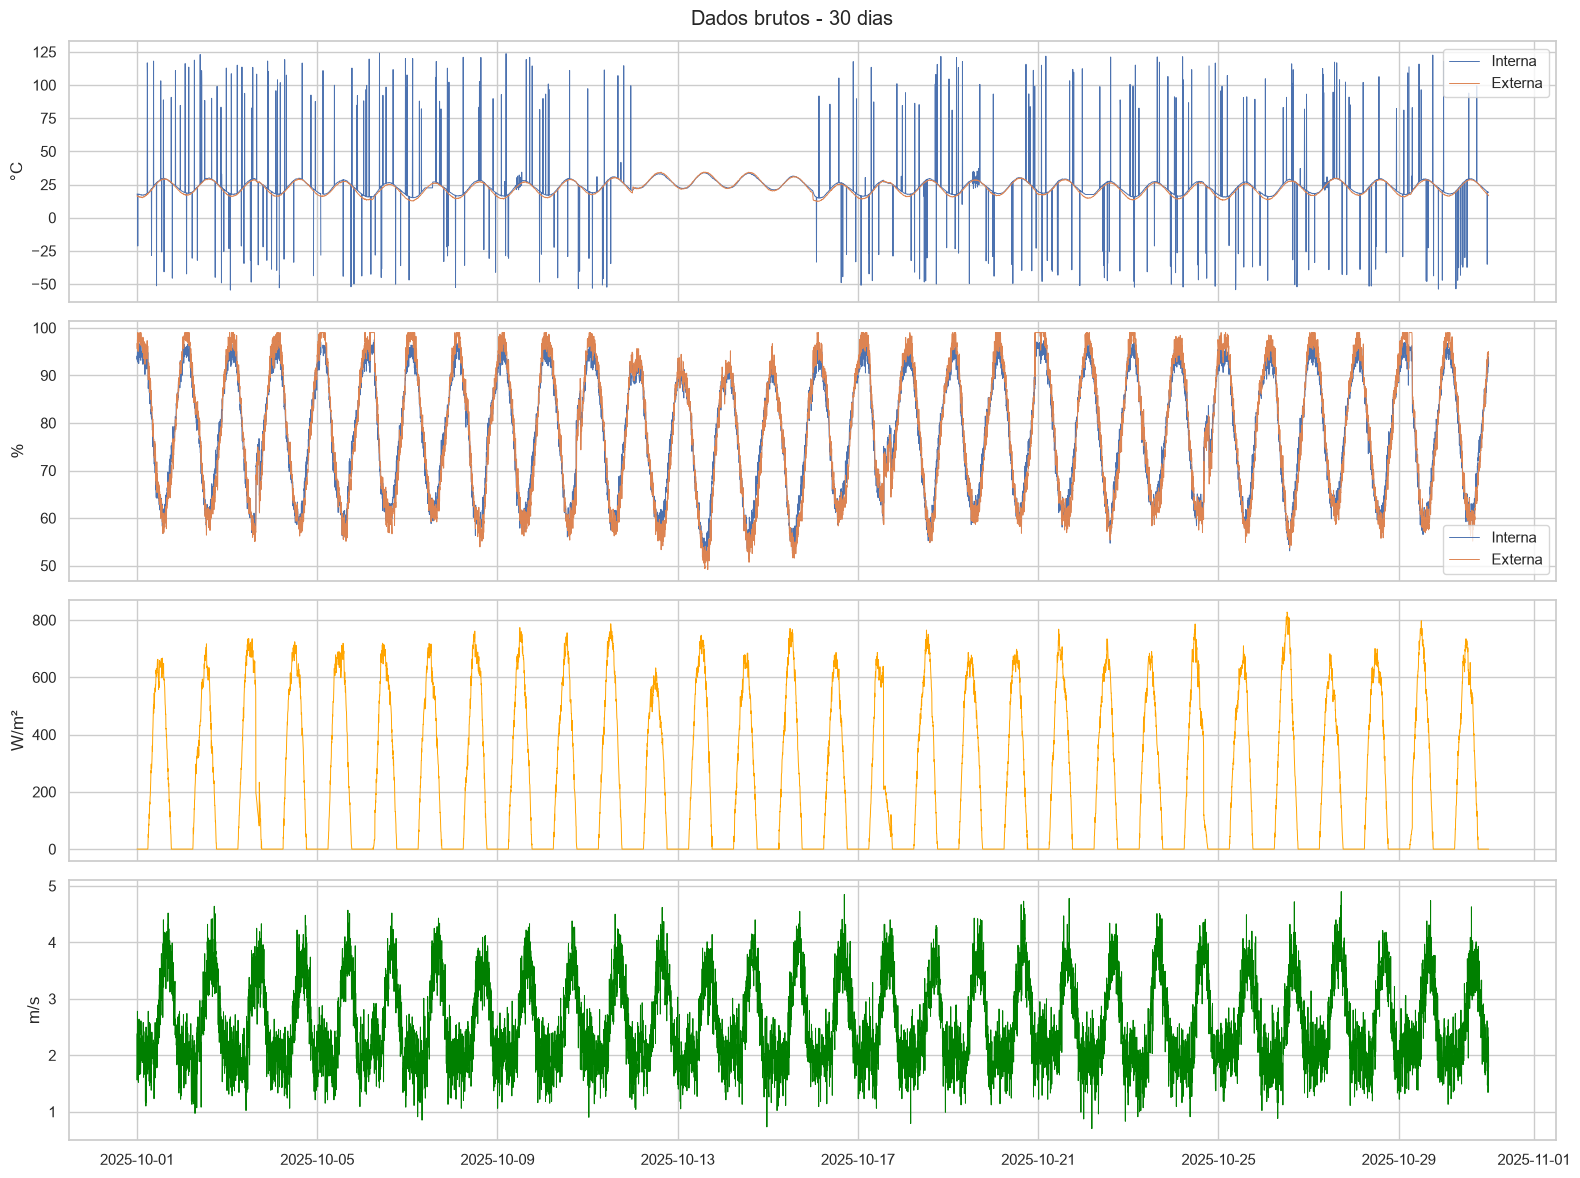

In [4]:
fig,axs=plt.subplots(4,1,figsize=(16,12),sharex=True)
axs[0].plot(dados.timestamp,dados.temperatura_interna_C,label='Interna',lw=.7); axs[0].plot(dados.timestamp,dados.temperatura_ambiente_C,label='Externa',lw=.7); axs[0].legend(); axs[0].set_ylabel('°C')
axs[1].plot(dados.timestamp,dados.umidade_relativa_interna_pct,label='Interna',lw=.7); axs[1].plot(dados.timestamp,dados.umidade_relativa_ar_pct,label='Externa',lw=.7); axs[1].legend(); axs[1].set_ylabel('%')
axs[2].plot(dados.timestamp,dados.radiacao_solar_global_W_m2,color='orange',lw=.7); axs[2].set_ylabel('W/m²')
axs[3].plot(dados.timestamp,dados.velocidade_vento_m_s,color='green',lw=.7); axs[3].set_ylabel('m/s')
fig.suptitle('Dados brutos - 30 dias'); fig.tight_layout(); fig.savefig(ROOT/'resultados/figuras/dados_brutos/02_series_30_dias.png',dpi=150); plt.show()

## Distribuições e correlações

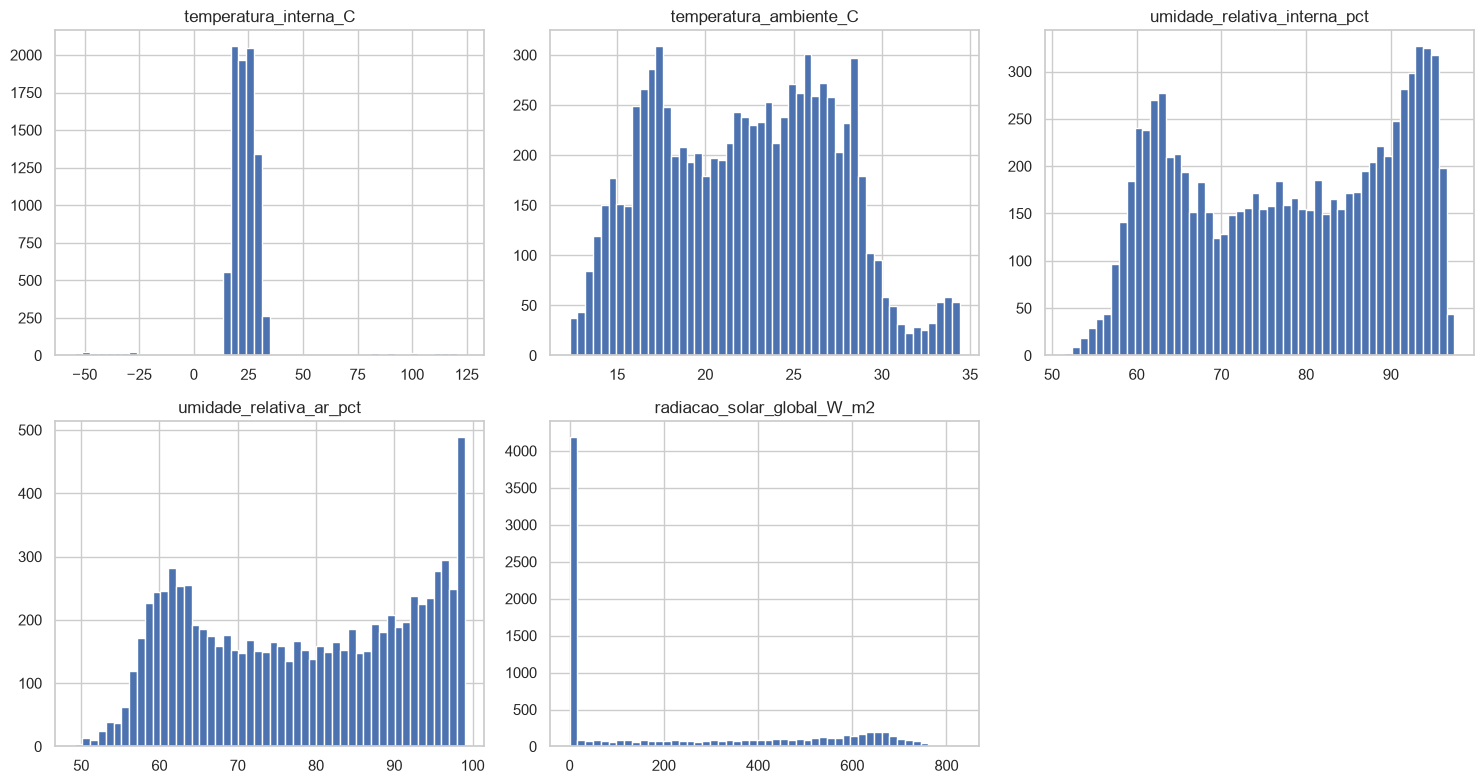

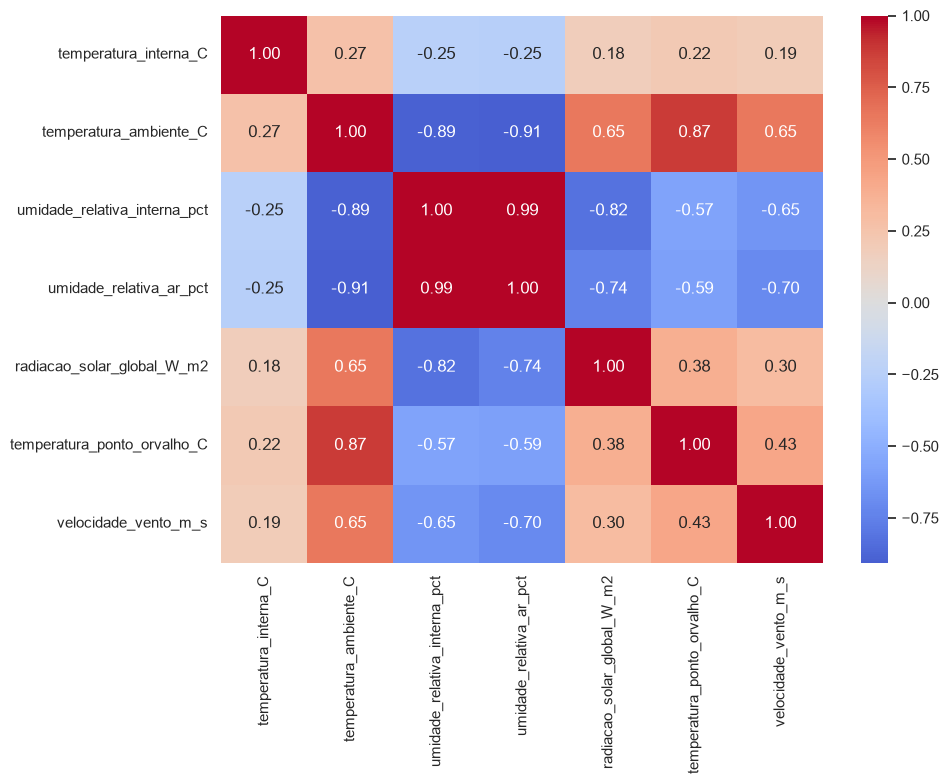

In [5]:
cols=['temperatura_interna_C','temperatura_ambiente_C','umidade_relativa_interna_pct','umidade_relativa_ar_pct','radiacao_solar_global_W_m2']
fig,axs=plt.subplots(2,3,figsize=(15,8));
for ax,c in zip(axs.ravel(),cols): ax.hist(dados[c].dropna(),bins=50); ax.set_title(c)
axs.ravel()[-1].axis('off'); fig.tight_layout(); fig.savefig(ROOT/'resultados/figuras/dados_brutos/03_distribuicoes.png',dpi=150); plt.show()
plt.figure(figsize=(10,8)); sns.heatmap(dados[cols+['temperatura_ponto_orvalho_C','velocidade_vento_m_s']].corr(),annot=True,fmt='.2f',cmap='coolwarm',center=0); plt.tight_layout(); plt.savefig(ROOT/'resultados/figuras/dados_brutos/04_correlacoes.png',dpi=150); plt.show()

## Eventos conhecidos

,registros
evento_referencia,
normal,6817
onda_de_calor_real,1152
valor_fisicamente_impossivel,346
sensor_travado_temperatura,103
ruido_excessivo_temperatura,102
dado_faltante_aleatorio,86
falha_de_comunicacao,24
pico_isolado_desconhecido,10


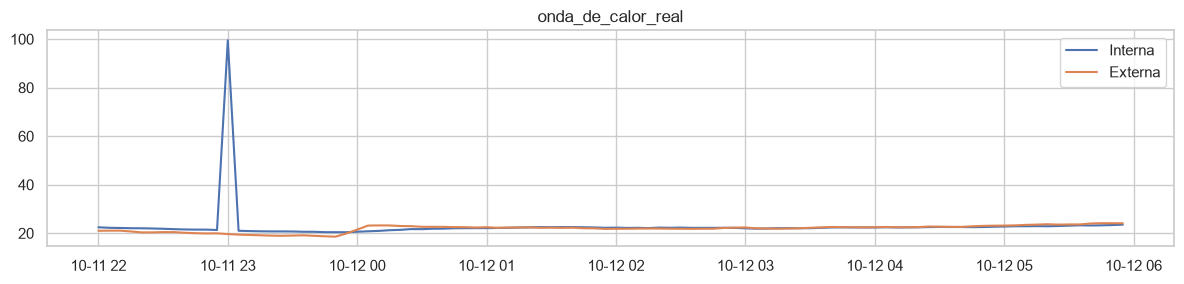

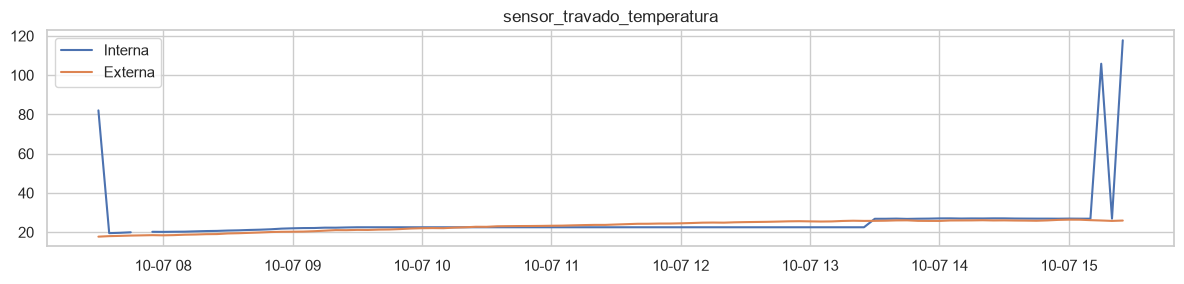

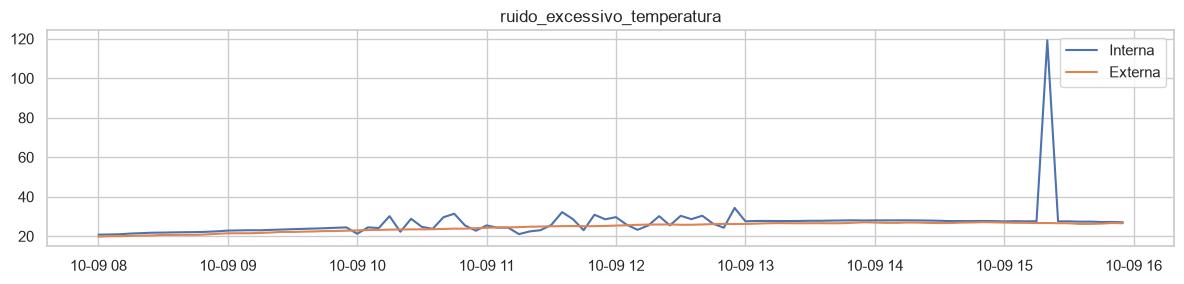

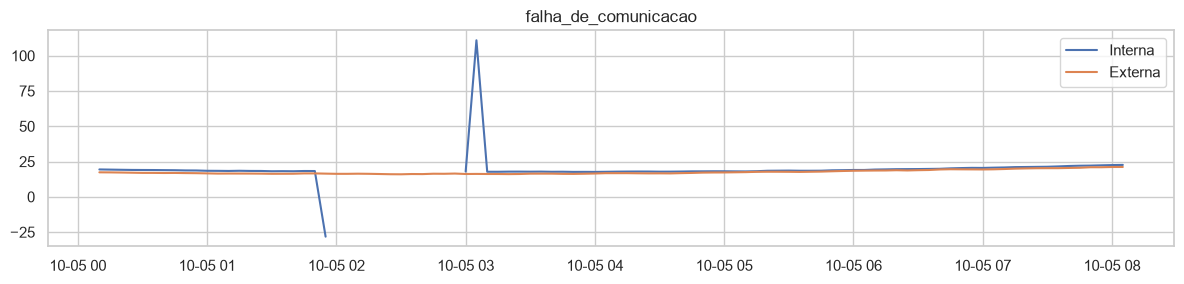

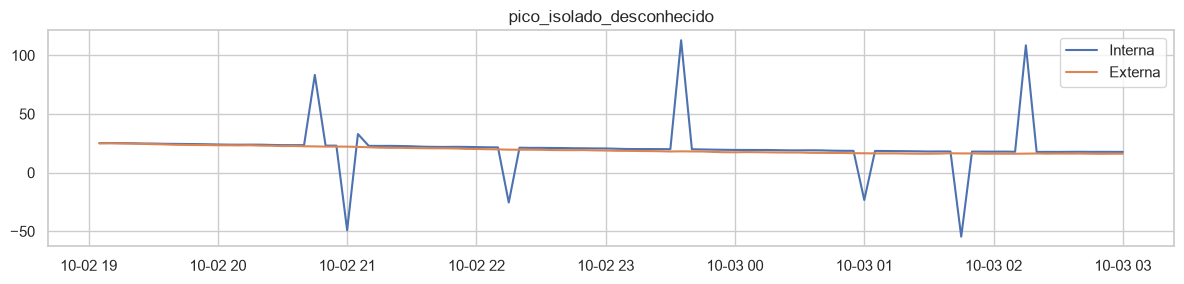

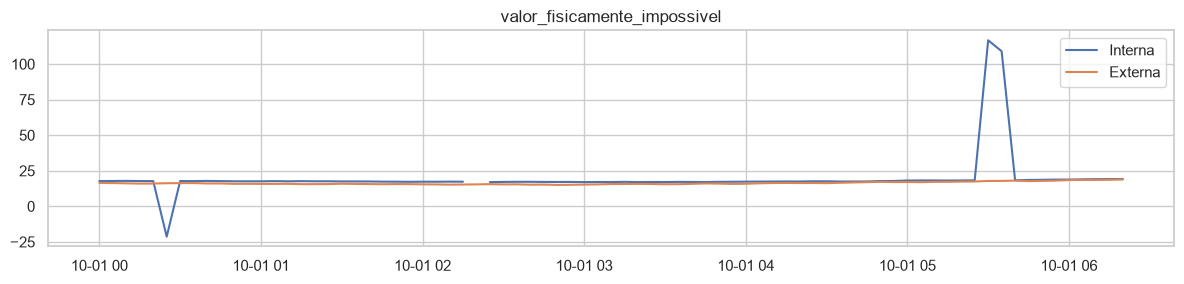

In [7]:
display(dados.evento_referencia.value_counts().to_frame('registros'))
for evento in ['onda_de_calor_real','sensor_travado_temperatura','ruido_excessivo_temperatura','falha_de_comunicacao','pico_isolado_desconhecido','valor_fisicamente_impossivel']:
    m=dados.evento_referencia.eq(evento)
    if not m.any(): continue
    i=np.where(m)[0][0]; rec=dados.iloc[max(0,i-24):min(len(dados),i+72)]
    fig,ax=plt.subplots(figsize=(12,3)); ax.plot(rec.timestamp,rec.temperatura_interna_C,label='Interna'); ax.plot(rec.timestamp,rec.temperatura_ambiente_C,label='Externa'); ax.set_title(evento); ax.legend(); fig.tight_layout(); fig.savefig(ROOT/f'resultados/figuras/dados_brutos/evento_{evento}.png',dpi=140); plt.show()

## Conclusões da etapa

Execute todas as células, registre as observações exibidas e confirme os arquivos gerados antes de avançar para o notebook seguinte.